<a href="https://colab.research.google.com/github/borisdayma/dalle-mini/blob/main/tools/inference/inference_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DALL·E mini - Inference pipeline

*Generate images from a text prompt*

<img src="https://github.com/borisdayma/dalle-mini/blob/main/img/logo.png?raw=true" width="200">

This notebook illustrates [DALL·E mini](https://github.com/borisdayma/dalle-mini) inference pipeline.

Just want to play? Use directly [the app](https://www.craiyon.com/).

For more understanding of the model, refer to [the report](https://wandb.ai/dalle-mini/dalle-mini/reports/DALL-E-mini--Vmlldzo4NjIxODA).

In [1]:
import os

## 🛠️ Installation and set-up

In [2]:
# Required only for colab environments + GPU
%pip install jax==0.3.25 \
https://storage.googleapis.com/jax-releases/cuda11/jaxlib-0.3.25+cuda11.cudnn805-cp310-cp310-manylinux2014_x86_64.whl


# Install required libraries
%pip install -q dalle-mini
%pip install -q git+https://github.com/patil-suraj/vqgan-jax.git

  Using cached https://storage.googleapis.com/jax-releases/cuda11/jaxlib-0.3.25+cuda11.cudnn805-cp310-cp310-manylinux2014_x86_64.whl (241.6 MB)

[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
#We load required models:
#* DALL·E mini for text to encoded images
#* VQGAN for decoding images
#* CLIP for scoring predictions

In [4]:
# Model references

# dalle-mega
#DALLE_MODEL = "/home/kstro/proyectos/dalle-mini/dalle-mini-main/outputs/dalle-model-768-recaptioned"  # can be wandb artifact or 🤗 Hub or local folder or google bucket
DALLE_COMMIT_ID = None

# if the notebook crashes too often you can use dalle-mini instead by uncommenting below line
DALLE_MODEL = "dalle-mini/dalle-mini/mini-1:v0"

# VQGAN model
VQGAN_REPO = "dalle-mini/vqgan_imagenet_f16_16384"
VQGAN_COMMIT_ID = "e93a26e7707683d349bf5d5c41c5b0ef69b677a9"

In [5]:
import jax
import jax.numpy as jnp
import jaxlib
print("JAX version:", jax.__version__)
print("JAXLIB version:", jaxlib.__version__)
print("Available devices:", jax.devices())
# check how many devices are available

x = jnp.ones((1, 3, 64, 64))  # NCHW
w = jnp.ones((16, 3, 3, 3))   # OIHW
out = jax.lax.conv_general_dilated(
    x, w,
    window_strides=(1, 1),
    padding="SAME",
    dimension_numbers=("NCHW", "OIHW", "NCHW")
)
print(out.shape)


JAX version: 0.3.25
JAXLIB version: 0.3.25
Available devices: [StreamExecutorGpuDevice(id=0, process_index=0, slice_index=0)]
(1, 16, 64, 64)


In [6]:
# Load models & tokenizer
from dalle_mini import DalleBart, DalleBartProcessor
from vqgan_jax.modeling_flax_vqgan import VQModel
from transformers import CLIPProcessor, FlaxCLIPModel

# Load dalle-mini
model, params = DalleBart.from_pretrained(
    DALLE_MODEL, revision=DALLE_COMMIT_ID, dtype=jnp.float16, _do_init=False
)

#Load VQGAN
vqgan, vqgan_params = VQModel.from_pretrained(
    VQGAN_REPO, revision=VQGAN_COMMIT_ID, _do_init=False
)

wandb: Downloading large artifact mini-1:v0, 1673.43MB. 7 files... 
wandb:   7 of 7 files downloaded.  
Done. 0:0:7.6 (218.8MB/s)
/home/kstro/dalle-env/lib/python3.10/site-packages/huggingface_hub/file_download.py:943: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Model parameters are replicated on each device for faster inference.

In [7]:
from flax.jax_utils import replicate

params = replicate(params)
vqgan_params = replicate(vqgan_params)

Model functions are compiled and parallelized to take advantage of multiple devices.

In [8]:
from functools import partial


# model inference
@partial(jax.pmap, axis_name="batch", static_broadcasted_argnums=(3, 4, 5, 6))
def p_generate(
    tokenized_prompt, key, params, top_k, top_p, temperature, condition_scale
):
    return model.generate(
        **tokenized_prompt,
        prng_key=key,
        params=params,
        top_k=top_k,
        top_p=top_p,
        temperature=temperature,
        condition_scale=condition_scale,
    )


# decode image
@partial(jax.pmap, axis_name="batch")
def p_decode(indices, params):
    return vqgan.decode_code(indices, params=params)

Keys are passed to the model on each device to generate unique inference per device.

In [9]:
import random

# create a random key
seed = 42
key = jax.random.PRNGKey(seed)

## 🖍 Text Prompt

Our model requires processing prompts.

In [10]:
from dalle_mini import DalleBartProcessor

processor = DalleBartProcessor.from_pretrained(DALLE_MODEL, revision=DALLE_COMMIT_ID)

wandb: Downloading large artifact mini-1:v0, 1673.43MB. 7 files... 
wandb:   7 of 7 files downloaded.  
Done. 0:0:2.4 (690.3MB/s)


Let's define some text prompts.

In [11]:
prompts = [
    "sunset over a lake in the mountains",
    "the Eiffel tower landing on the moon",
]

Note: we could use the same prompt multiple times for faster inference.

In [12]:
tokenized_prompts = processor(prompts)

Finally we replicate the prompts onto each device.

In [13]:
tokenized_prompt = replicate(tokenized_prompts)

## 🎨 Generate images

We generate images using dalle-mini model and decode them with the VQGAN.

In [14]:
# number of predictions per prompt
n_predictions = 8

# We can customize generation parameters (see https://huggingface.co/blog/how-to-generate)
gen_top_k = None
gen_top_p = None
temperature = None 
cond_scale = 10

Prompts: ['sunset over a lake in the mountains', 'the Eiffel tower landing on the moon']



  0%|          | 0/8 [00:00<?, ?it/s]

/home/kstro/dalle-env/lib/python3.10/site-packages/jax/_src/ops/scatter.py:87: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float16 to dtype=float32. In future JAX releases this will result in an error.
  warnings.warn("scatter inputs have incompatible types: cannot safely cast "


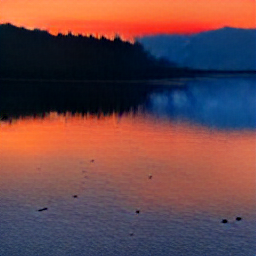

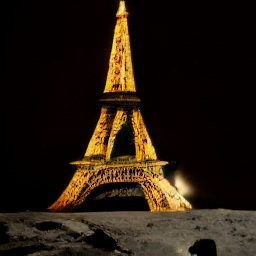

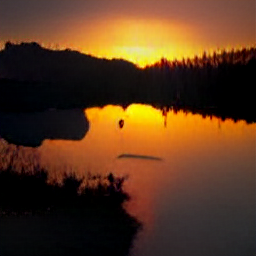

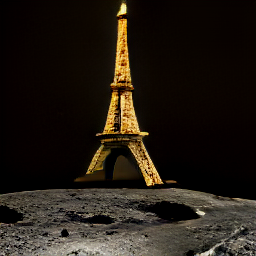

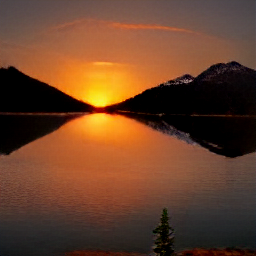

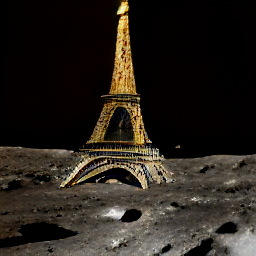

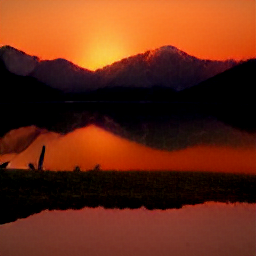

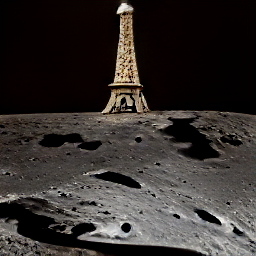

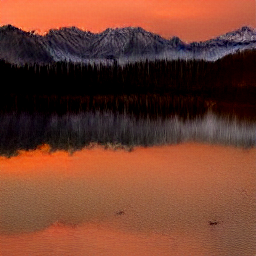

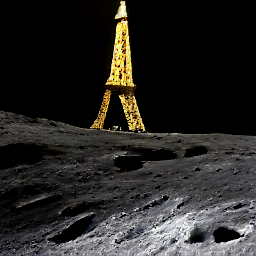

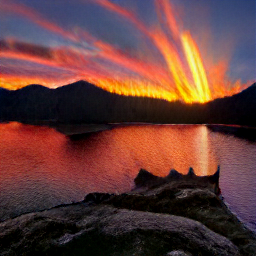

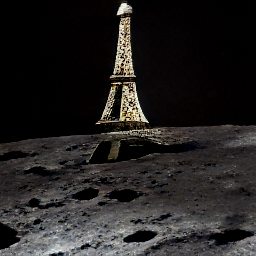

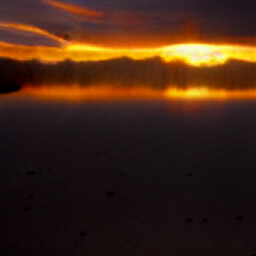

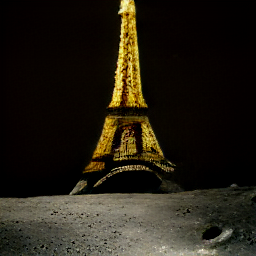

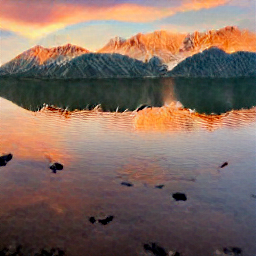

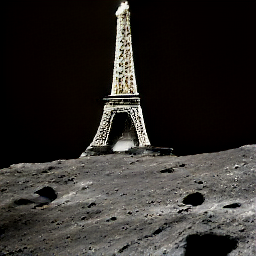

In [15]:
from flax.training.common_utils import shard_prng_key
import numpy as np
from PIL import Image
from tqdm.notebook import trange

print(f"Prompts: {prompts}\n")
# generate images
images = []
for i in trange(max(n_predictions // jax.device_count(), 1)):
    # get a new key
    key, subkey = jax.random.split(key)
    # generate images
    encoded_images = p_generate(
        tokenized_prompt,
        shard_prng_key(subkey),
        params,
        gen_top_k,
        gen_top_p,
        temperature,
        cond_scale,
    )
    # remove BOS
    #encoded_images = encoded_images.sequences[..., 1:]
    #print(encoded_images)
    # decode images

    # encoded_images.sequences shape: (n_devices, batch_per_device, 1 + image_length)
    seqs = encoded_images.sequences
    assert seqs.shape[-1] in (256+1, 256), f"Longitud inesperada: {seqs.shape}"

    
    # Si trae BOS de imagen, debe ser 16384 en la primera posición
    if seqs.shape[-1] == 257:
        first_tok = np.array(seqs[..., 0])
        #print("Primer token (esperado 16384):", int(first_tok.flatten()[0]))
        assert int(first_tok.flatten()[0]) == 16384, "IMG_BOS inesperado"
        encoded_images = seqs[..., 1:]
    else:
        encoded_images = seqs

    #tokens para el EB
    gen_tokens_no_bos = np.asarray(encoded_images)[0, 0]
    
    assert encoded_images.shape[-1] == 256, "image_length debe ser 256"

    #print(encoded_images)
    
    decoded_images = p_decode(encoded_images, vqgan_params)
    decoded_images = decoded_images.clip(0.0, 1.0).reshape((-1, 256, 256, 3))
    for decoded_img in decoded_images:
        img = Image.fromarray(np.asarray(decoded_img * 255, dtype=np.uint8))
        images.append(img)
        display(img)
        print()

In [16]:
## Reconstrucción de imagen del Dataset

  0%|          | 0/1 [00:00<?, ?it/s]

len(enc) = 256
decoded min/max: 0.0 1.0


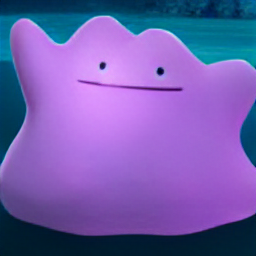

In [96]:
import numpy as np, jax.numpy as jnp
from PIL import Image
from datasets import load_dataset

def show_uint8(img01):
    img = (np.clip(img01, 0.0, 1.0) * 255).astype(np.uint8)
    display(Image.fromarray(img))

def decode_dataset_encoding(raw_encoding, vqgan_params, image_length=256):
    """
    raw_encoding: list[int] o np.array[int] de TU DATASET (no generado).
    No añadimos BOS. Suponemos que el VQ espera exactamente image_length tokens.
    """
    enc = np.array(raw_encoding, dtype=np.int32)
    print("len(enc) =", len(enc))
    assert len(enc) == image_length, "El encoding del dataset no coincide con image_length"
    # p_decode espera [n_devices, per_device_batch, L]
    seq = jnp.array(enc)[None, None, :]          # [1,1,L]
    decoded = p_decode(seq, vqgan_params)        # típicamente en [-1,1]
    img01 = np.clip((np.array(decoded)[0,0] + 1.0)/2.0, 0.0, 1.0)  # [H,W,3]
    print("decoded min/max:", float(img01.min()), float(img01.max()))
    show_uint8(img01)

# EJEMPLO de uso:
#/home/kstro/proyectos/dalle-mini/dalle-mini-main/
#/mnt/c/Users/Andrés Castro/Documents/GitHub/TesisBackend/backend/dalle-mini-main/tools/dataset/encoded_data/train/*.parquet
ds = load_dataset("parquet", data_files={"train": ["/home/kstro/proyectos/dalle-mini/dalle-mini-main/tools/dataset/encoded_data/subset-data/*.parquet"]}, streaming=False)["train"]
row = ds[151]
decode_dataset_encoding(row["encoding"], vqgan_params, image_length=256)


In [18]:
## Excitation Backpropagation

In [19]:
# Listar todas las rutas de parámetros
import jax
from flax.traverse_util import flatten_dict
from flax.jax_utils import unreplicate

params_single = unreplicate(params)

flat = flatten_dict(params_single, sep='.')
names = sorted(flat.keys())

print("Total params:", len(names))
print("Ejemplos de rutas:")
for k in names[:40]:
    print(" -", k)

print("\nRutas relevantes (GLU Dense y lm_head):")
for k in names:
    if ("model.decoder.layers." in k and "GLU_0.Dense_" in k and ".kernel" in k) or (k == "lm_head.kernel"):
        print(" *", k)

Total params: 42
Ejemplos de rutas:
 - lm_head.kernel
 - model.decoder.embed_positions.embedding
 - model.decoder.embed_tokens.embedding
 - model.decoder.final_ln.bias
 - model.decoder.layernorm_embedding.bias
 - model.decoder.layernorm_embedding.scale
 - model.decoder.layers.FlaxBartDecoderLayers.FlaxBartAttention_0.k_proj.kernel
 - model.decoder.layers.FlaxBartDecoderLayers.FlaxBartAttention_0.out_proj.kernel
 - model.decoder.layers.FlaxBartDecoderLayers.FlaxBartAttention_0.q_proj.kernel
 - model.decoder.layers.FlaxBartDecoderLayers.FlaxBartAttention_0.v_proj.kernel
 - model.decoder.layers.FlaxBartDecoderLayers.FlaxBartAttention_1.k_proj.kernel
 - model.decoder.layers.FlaxBartDecoderLayers.FlaxBartAttention_1.out_proj.kernel
 - model.decoder.layers.FlaxBartDecoderLayers.FlaxBartAttention_1.q_proj.kernel
 - model.decoder.layers.FlaxBartDecoderLayers.FlaxBartAttention_1.v_proj.kernel
 - model.decoder.layers.FlaxBartDecoderLayers.GLU_0.Dense_0.kernel
 - model.decoder.layers.FlaxBartDeco

In [20]:
#Añadir IDs de posición para el llamado directo al módulo
import jax.numpy as jnp

# Asegura dtypes
enc_input_ids = jnp.array(tokenized_prompts["input_ids"][0:1], dtype=jnp.int32)
enc_attention_mask = jnp.array(tokenized_prompts["attention_mask"][0:1], dtype=jnp.int32)

start_id = int(model.config.decoder_start_token_id)
decoder_input_ids = jnp.concatenate(
    [jnp.array([[start_id]], dtype=jnp.int32),
     jnp.array(gen_tokens_no_bos[:-1], dtype=jnp.int32)[None, :]],
    axis=1
)
decoder_attention_mask = jnp.ones_like(decoder_input_ids, dtype=jnp.int32)


# Construye position_ids y decoder_position_ids
pos_enc = jnp.arange(enc_input_ids.shape[1], dtype=jnp.int32)[None, :]
pos_dec = jnp.arange(decoder_input_ids.shape[1], dtype=jnp.int32)[None, :]

inputs_for_this_example = {
    "input_ids": enc_input_ids,
    "attention_mask": enc_attention_mask,
    "decoder_input_ids": decoder_input_ids,
    "decoder_attention_mask": decoder_attention_mask,
    "position_ids": pos_enc,
    "decoder_position_ids": pos_dec,
}

In [21]:

import jax
import jax.numpy as jnp

# 1) Forward único (sin pmap) para obtener logits de este ejemplo
y_out_top, _ = model.module.apply(
    {"params": params_single},
    **inputs_for_this_example,
    capture_intermediates=False,
    mutable=[],
)
# logits: [1, tgt_len, vocab]
logits_last = jnp.array(y_out_top.logits[0, -1])  # [vocab]

# 2) Pesos de lm_head
W_lm = params_single["lm_head"]["kernel"]         # [hidden, vocab]

# 3) h_last consistente con logits: logits ≈ h_last @ W_lm
#    h_last ≈ logits @ pinv(W_lm) ; (pinv retorna [vocab, hidden])
pinv_W = jnp.linalg.pinv(W_lm)                    # [vocab, hidden]
h_last = logits_last @ pinv_W                     # [hidden]

In [22]:
#EB para Dense
import jax
import jax.numpy as jnp

def eb_dense(activations, W, bottomP, eps=1e-12):
    """
    activations: [feat] (o [seq, feat]/[batch, seq, feat] si vectorizas)
    W: [in_dim, out_dim]
    bottomP: [out_dim] (p. ej., one-hot del token objetivo)
    devuelve: [in_dim]
    """
    W_pos = jnp.maximum(W, 0.0)
    # pcond = diag(a) @ W_pos = a[:,None] * W_pos
    pcond = activations[:, None] * W_pos       # [in_dim, out_dim]
    col_sums = jnp.sum(pcond, axis=0) + eps
    pcond = pcond / col_sums
    p_in = pcond @ bottomP                     # [in_dim]
    return p_in

In [23]:
import numpy as np

try:
    target_token_id = int(gen_tokens_no_bos[-1])
except NameError:
    try:
        target_token_id = int(np.asarray(encoded_images)[0, 0, -1])
    except Exception:
        target_token_id = int(jnp.argmax(logits_last))

print("target_token_id:", target_token_id)

vocab_size = W_lm.shape[1]
bottom_vocab = jax.nn.one_hot(target_token_id, vocab_size, dtype=jnp.float32)

# Ejecutar EB para lm_head
p_hidden = eb_dense(h_last, W_lm, bottom_vocab) 
print("p_hidden shape:", p_hidden.shape)

#sanity checks
assert p_hidden.ndim == 1, "p_hidden debe ser un vector [hidden]"
assert p_hidden.shape[0] == W_lm.shape[0], "Dim hidden no coincide con W_lm"

target_token_id: 6523
p_hidden shape: (1024,)


In [24]:
#Top-k hidden
import numpy as np

def topk(v, k=10):
    v = np.asarray(v)
    idx = v.argsort()[-k:][::-1]
    return idx, v[idx]

idx_h, val_h = topk(p_hidden, 10)
print("lm_head hidden top-k indices:", idx_h.tolist())
print("lm_head hidden top-k values:", val_h.tolist())
print(float(np.asarray(p_hidden).sum()))
print(np.all(np.asarray(p_hidden) >= 0))

lm_head hidden top-k indices: [361, 124, 345, 272, 316, 720, 961, 881, 443, 507]
lm_head hidden top-k values: [0.012131912633776665, 0.011180179193615913, 0.011112848296761513, 0.011051315814256668, 0.011019865982234478, 0.010426891036331654, 0.01030200719833374, 0.010144142434000969, 0.010020818561315536, 0.009619997814297676]
1.0000001192092896
False


In [25]:
## CLIP

In [26]:
# CLIP model
CLIP_REPO = "openai/clip-vit-base-patch32"
CLIP_COMMIT_ID = None

# Load CLIP
clip, clip_params = FlaxCLIPModel.from_pretrained(
    CLIP_REPO, revision=CLIP_COMMIT_ID, dtype=jnp.float16, _do_init=False
)
clip_processor = CLIPProcessor.from_pretrained(CLIP_REPO, revision=CLIP_COMMIT_ID)
clip_params = replicate(clip_params)


# score images
@partial(jax.pmap, axis_name="batch")
def p_clip(inputs, params):
    logits = clip(params=params, **inputs).logits_per_image
    return logits

/home/kstro/dalle-env/lib/python3.10/site-packages/huggingface_hub/file_download.py:943: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [27]:
from flax.training.common_utils import shard

# get clip scores
clip_inputs = clip_processor(
    text=prompts * jax.device_count(),
    images=images,
    return_tensors="np",
    padding="max_length",
    max_length=77,
    truncation=True,
).data
logits = p_clip(shard(clip_inputs), clip_params)

# organize scores per prompt
p = len(prompts)
logits = np.asarray([logits[:, i::p, i] for i in range(p)]).squeeze()

Let's now display images ranked by CLIP score.

Prompt: sunset over a lake in the mountains



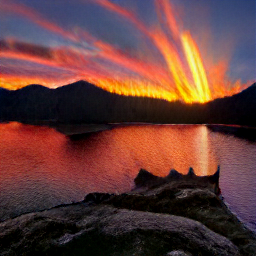

Score: 31.71



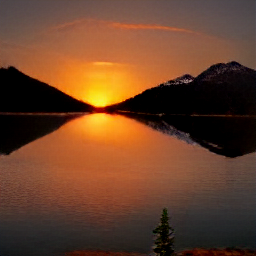

Score: 30.86



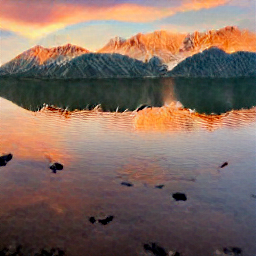

Score: 30.76



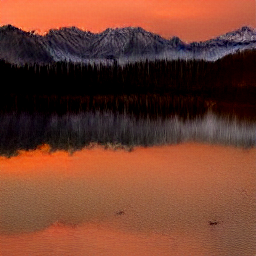

Score: 30.69



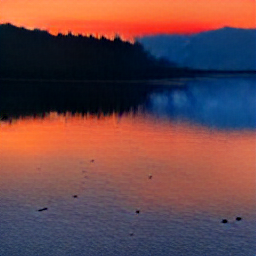

Score: 30.03



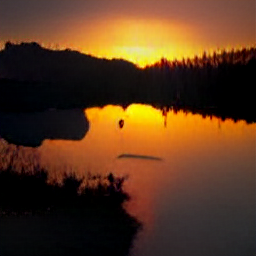

Score: 29.54



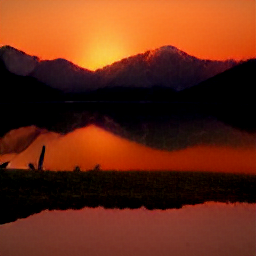

Score: 29.30



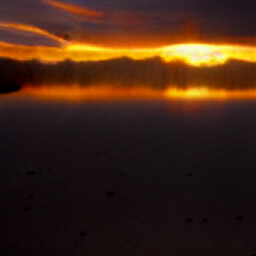

Score: 28.86


Prompt: the Eiffel tower landing on the moon



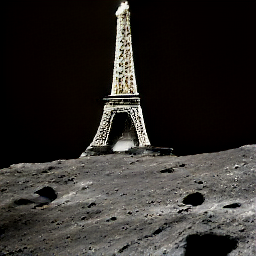

Score: 38.62



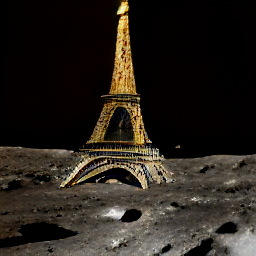

Score: 37.65



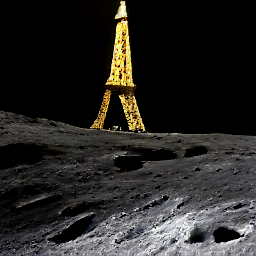

Score: 36.94



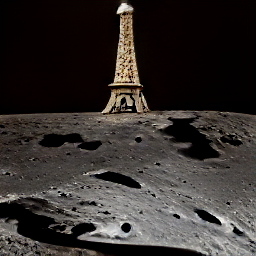

Score: 36.84



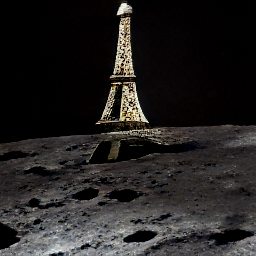

Score: 36.45



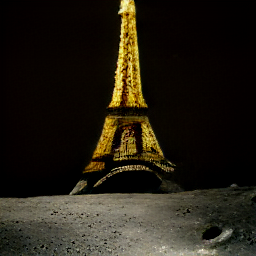

Score: 36.13



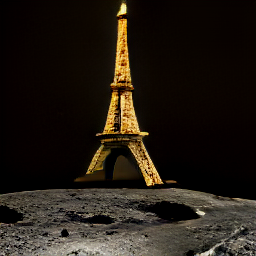

Score: 34.99



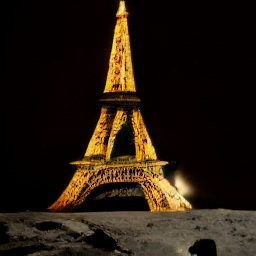

Score: 32.93




In [28]:
for i, prompt in enumerate(prompts):
    print(f"Prompt: {prompt}\n")
    for idx in logits[i].argsort()[::-1]:
        display(images[idx * p + i])
        print(f"Score: {jnp.asarray(logits[i][idx], dtype=jnp.float32):.2f}\n")
    print()

## 🪄 Optional: Save your Generated Images as W&B Tables

W&B Tables is an interactive 2D grid with support to rich media logging. Use this to save the generated images on W&B dashboard and share with the world.

In [29]:
import wandb

# Initialize a W&B run.
project = "dalle-mini-tables-colab"
run = wandb.init(project=project)

# Initialize an empty W&B Tables.
columns = ["captions"] + [f"image_{i+1}" for i in range(n_predictions)]
gen_table = wandb.Table(columns=columns)

# Add data to the table.
for i, prompt in enumerate(prompts):
    # If CLIP scores exist, sort the Images
    if logits is not None:
        idxs = logits[i].argsort()[::-1]
        tmp_imgs = images[i :: len(prompts)]
        tmp_imgs = [tmp_imgs[idx] for idx in idxs]
    else:
        tmp_imgs = images[i :: len(prompts)]

    # Add the data to the table.
    gen_table.add_data(prompt, *[wandb.Image(img) for img in tmp_imgs])

# Log the Table to W&B dashboard.
wandb.log({"Generated Images": gen_table})

# Close the W&B run.
run.finish()

wandb: Currently logged in as: castro-andres (castro-andres-universidad-metropolitana) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Click on the link above to check out your generated images.